In [1]:
### Importando bibliotecas

import matplotlib.pyplot as plt
import numpy as np 
import matplotlib as mpl 
import seaborn as sns
import scipy.integrate

custom_params = {'figure.dpi':500}
sns.set_theme(context='notebook', style='white', palette='deep', rc=custom_params)

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "font.size": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 15,
    "axes.titlesize": 15,
    "axes.unicode_minus": False,
})

### Exercício 2: 

#### a. Faça um gráfico de contorno da função de densidade de probabilidade conjunta a posteriori.

In [2]:
# definindo os parâmetros dados pelo exercício:

A1 = 4.82033
A2 = 4.43181
x1 = 0.5 
y1 = 0.5
x2 = 0.65
y2 = 0.75 
sigma_1 = 0.2
sigma_2 = 0.04

x = np. linspace(0, 1, 1000)
y = np.linspace(0, 1, 1000)

X, Y = np.meshgrid(x, y)

# Definindo a distribuição conjunta

pdf = A1*np.exp(-((X-x1)**2 + (Y-y1)**2)/(2*sigma_1**2)) + A2 * np.exp(-((X-x2)**2 + (Y-y2)**2)/(2*sigma_2**2))

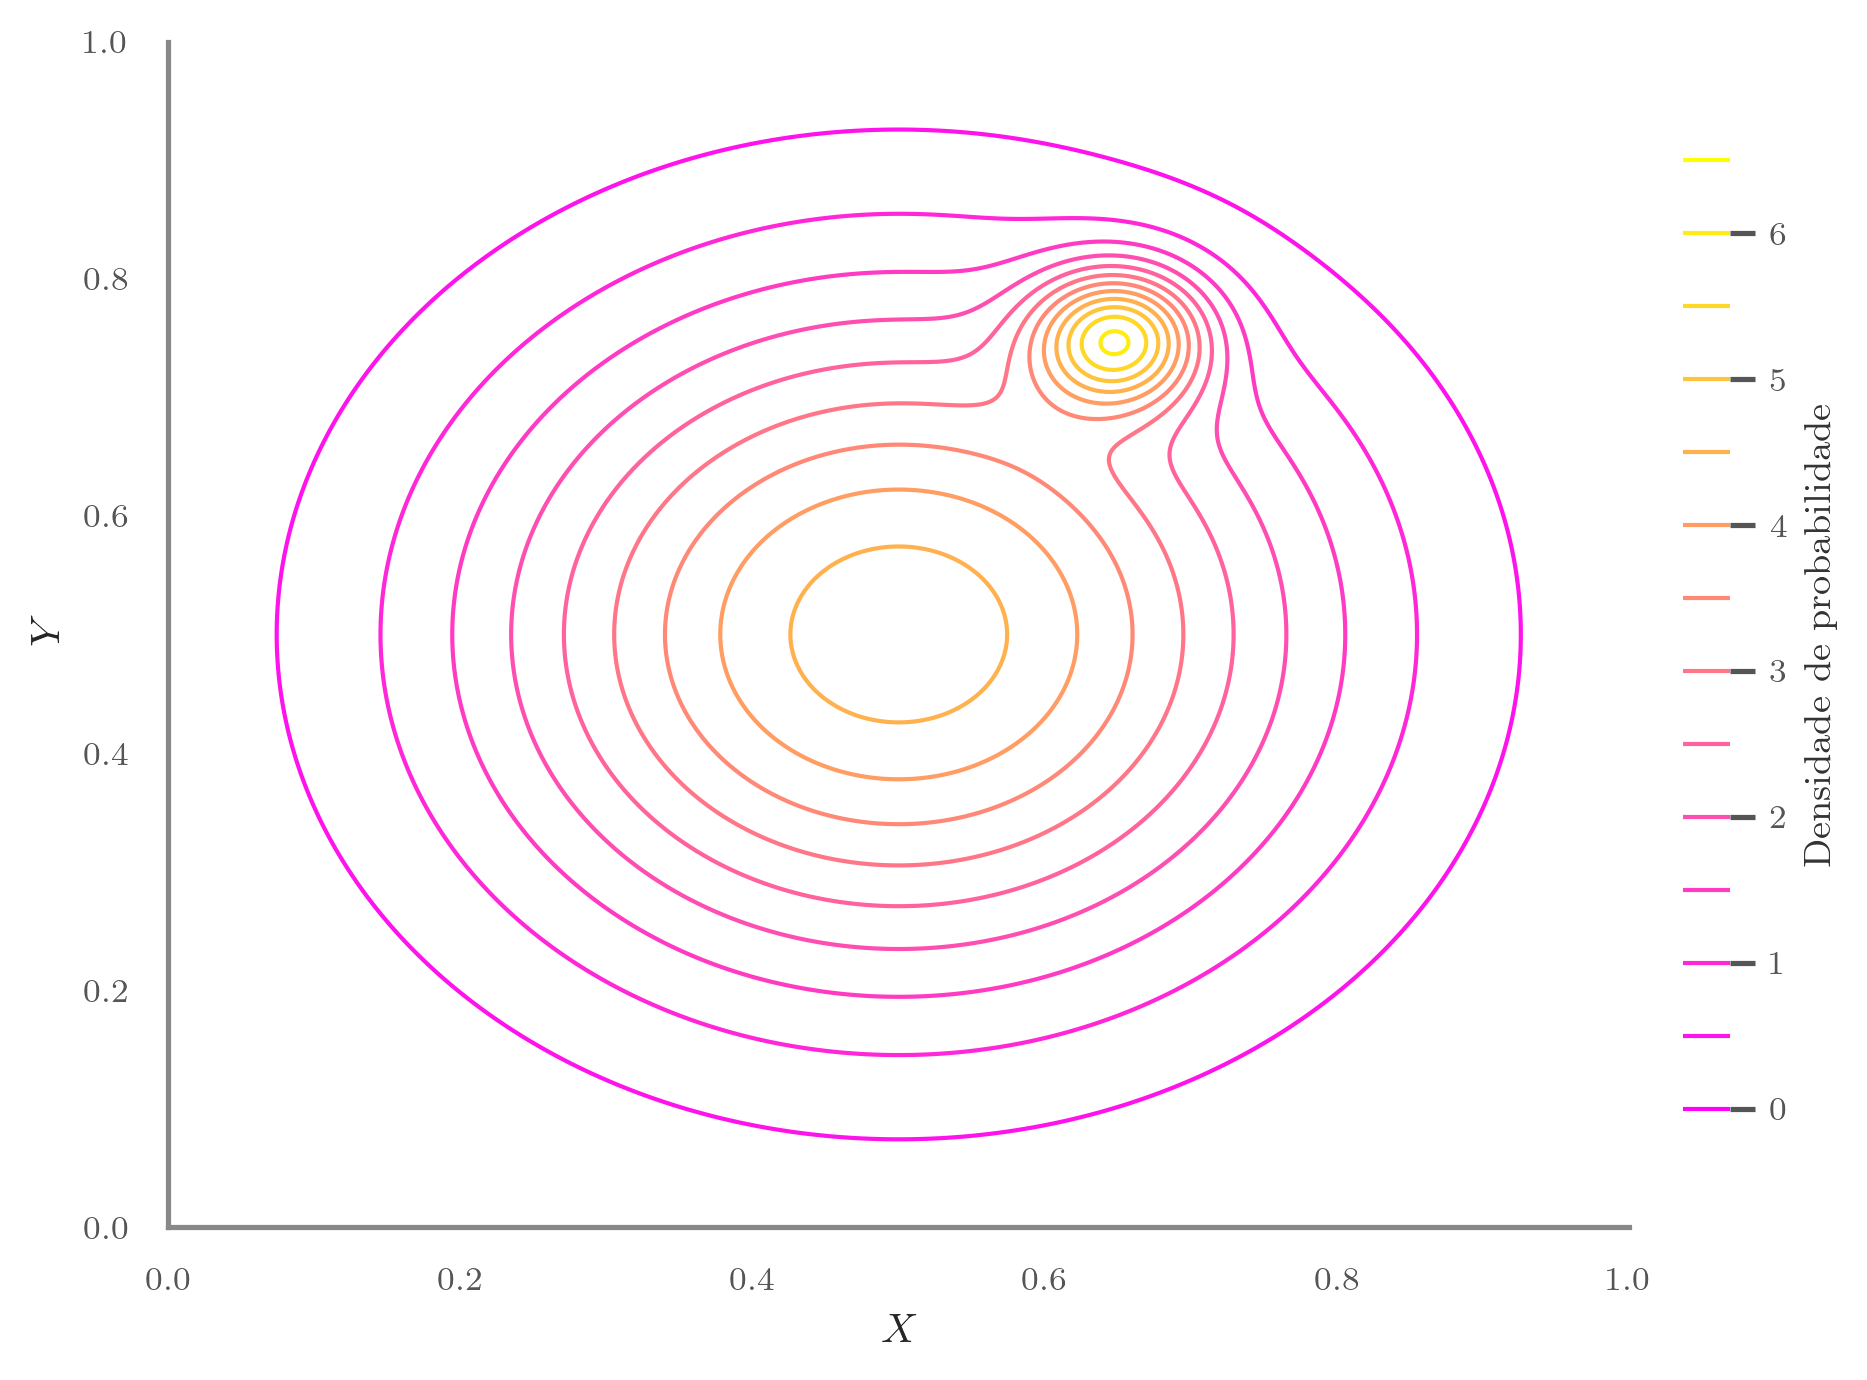

In [3]:
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)

contours = ax.contour(
    x, y, pdf,
    levels=12,
    cmap='spring',
    linewidths=1
)

cbar = fig.colorbar(contours, ax=ax, shrink=0.8, pad=0.03)
cbar.set_label('Densidade de probabilidade', fontsize=9, color='#333')
cbar.ax.tick_params(labelsize=8, colors='#555')
cbar.outline.set_visible(False)

ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#888')

ax.tick_params(colors='#555', labelsize=8)

ax.set_xlabel(r'$X$', fontsize=10)
ax.set_ylabel(r'$Y$', fontsize=10)

fig.tight_layout()

plt.show()

#### b. Gráfico tridimensional de $p(X,Y|D,M,I)$

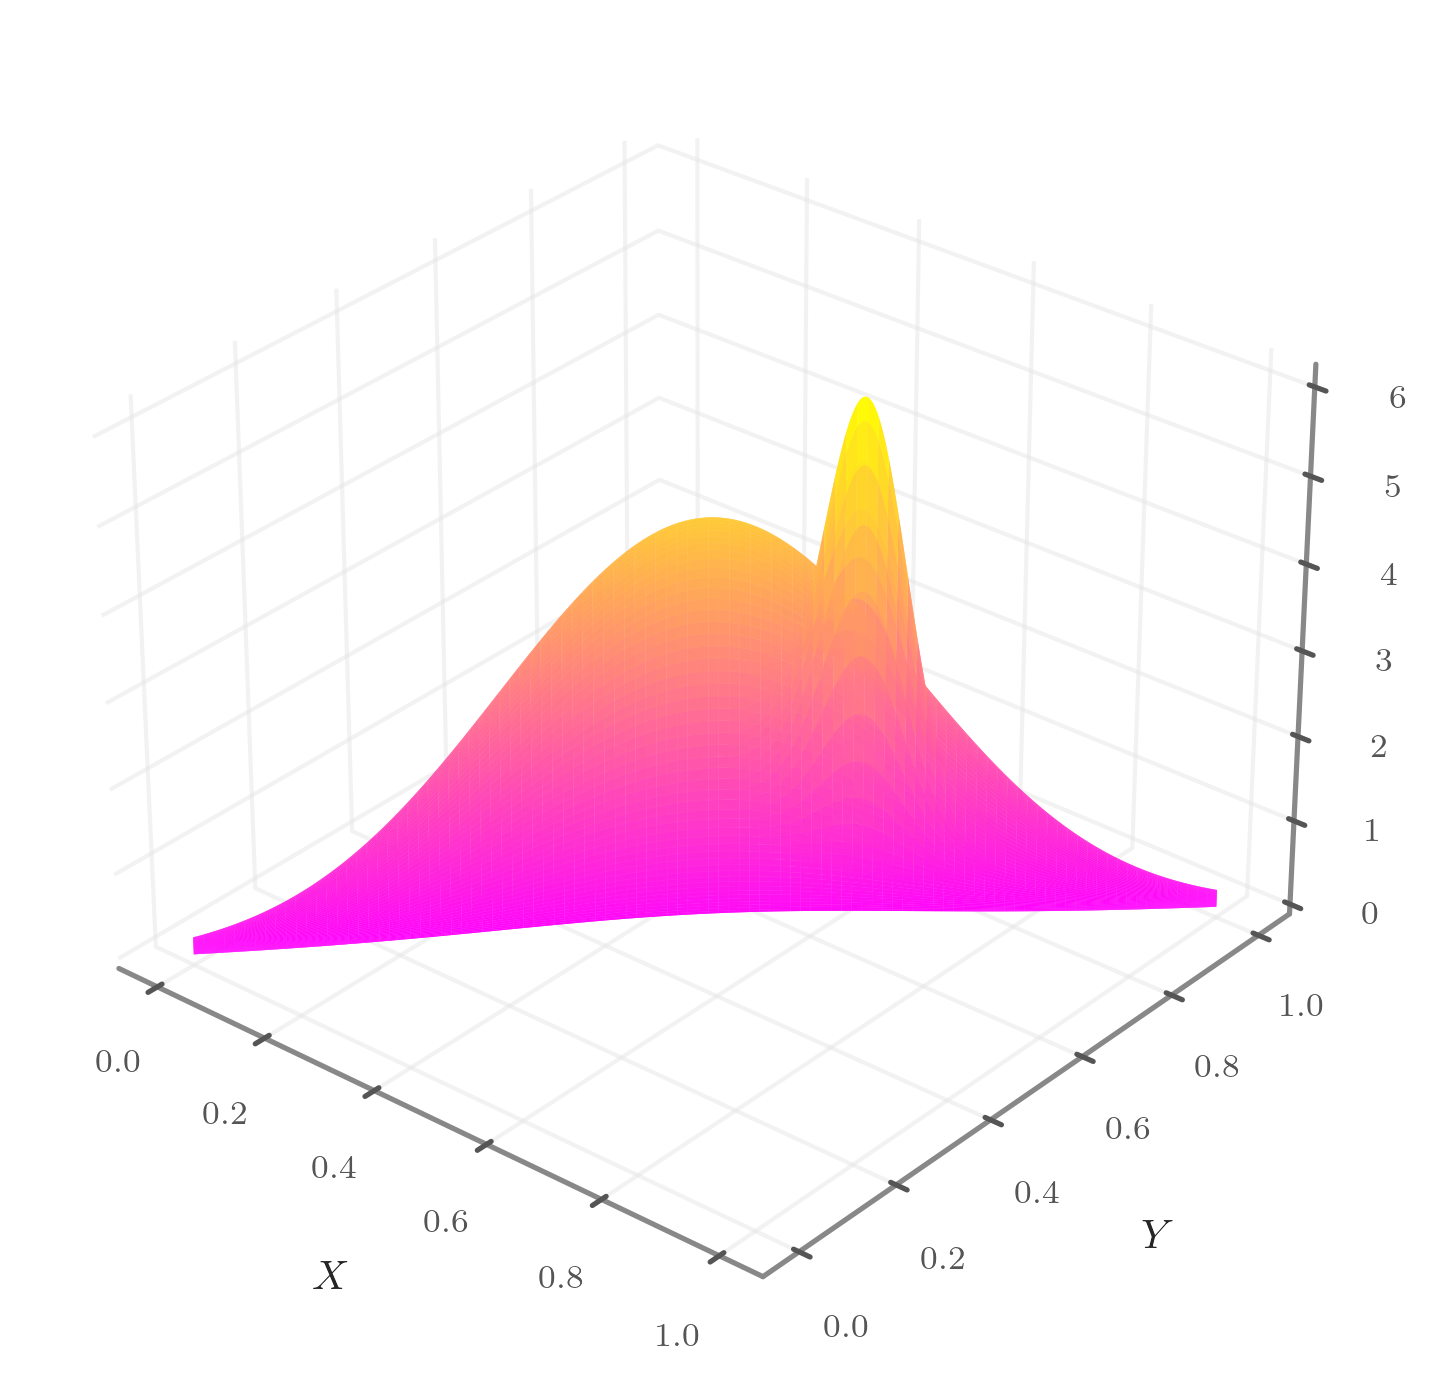

In [4]:
fig = plt.figure(figsize=(6, 5), dpi=300)

ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    x, y, pdf,
    cmap='spring',
    linewidth=0,
    antialiased=True,
    alpha=0.9,
    rcount=100,
    ccount=100
)

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax.xaxis.pane.set_edgecolor('none')
ax.yaxis.pane.set_edgecolor('none')
ax.zaxis.pane.set_edgecolor('none')

ax.xaxis._axinfo["grid"]['color'] = (0.9, 0.9, 0.9, 0.5)
ax.yaxis._axinfo["grid"]['color'] = (0.9, 0.9, 0.9, 0.5)
ax.zaxis._axinfo["grid"]['color'] = (0.9, 0.9, 0.9, 0.5)

ax.xaxis.line.set_color('#888')
ax.yaxis.line.set_color('#888')
ax.zaxis.line.set_color('#888')

ax.tick_params(colors='#555', labelsize=8)

ax.set_xlabel(r'$X$', fontsize=10, labelpad=8)
ax.set_ylabel(r'$Y$', fontsize=10, labelpad=8)
ax.set_zlabel('Densidade de probabilidade', fontsize=10, labelpad=8)

ax.view_init(elev=30, azim=-50)

fig.tight_layout()

plt.show()

Decomposição das duas gaussianas para melhor visualização da sobreposição da distribuição conjunta:

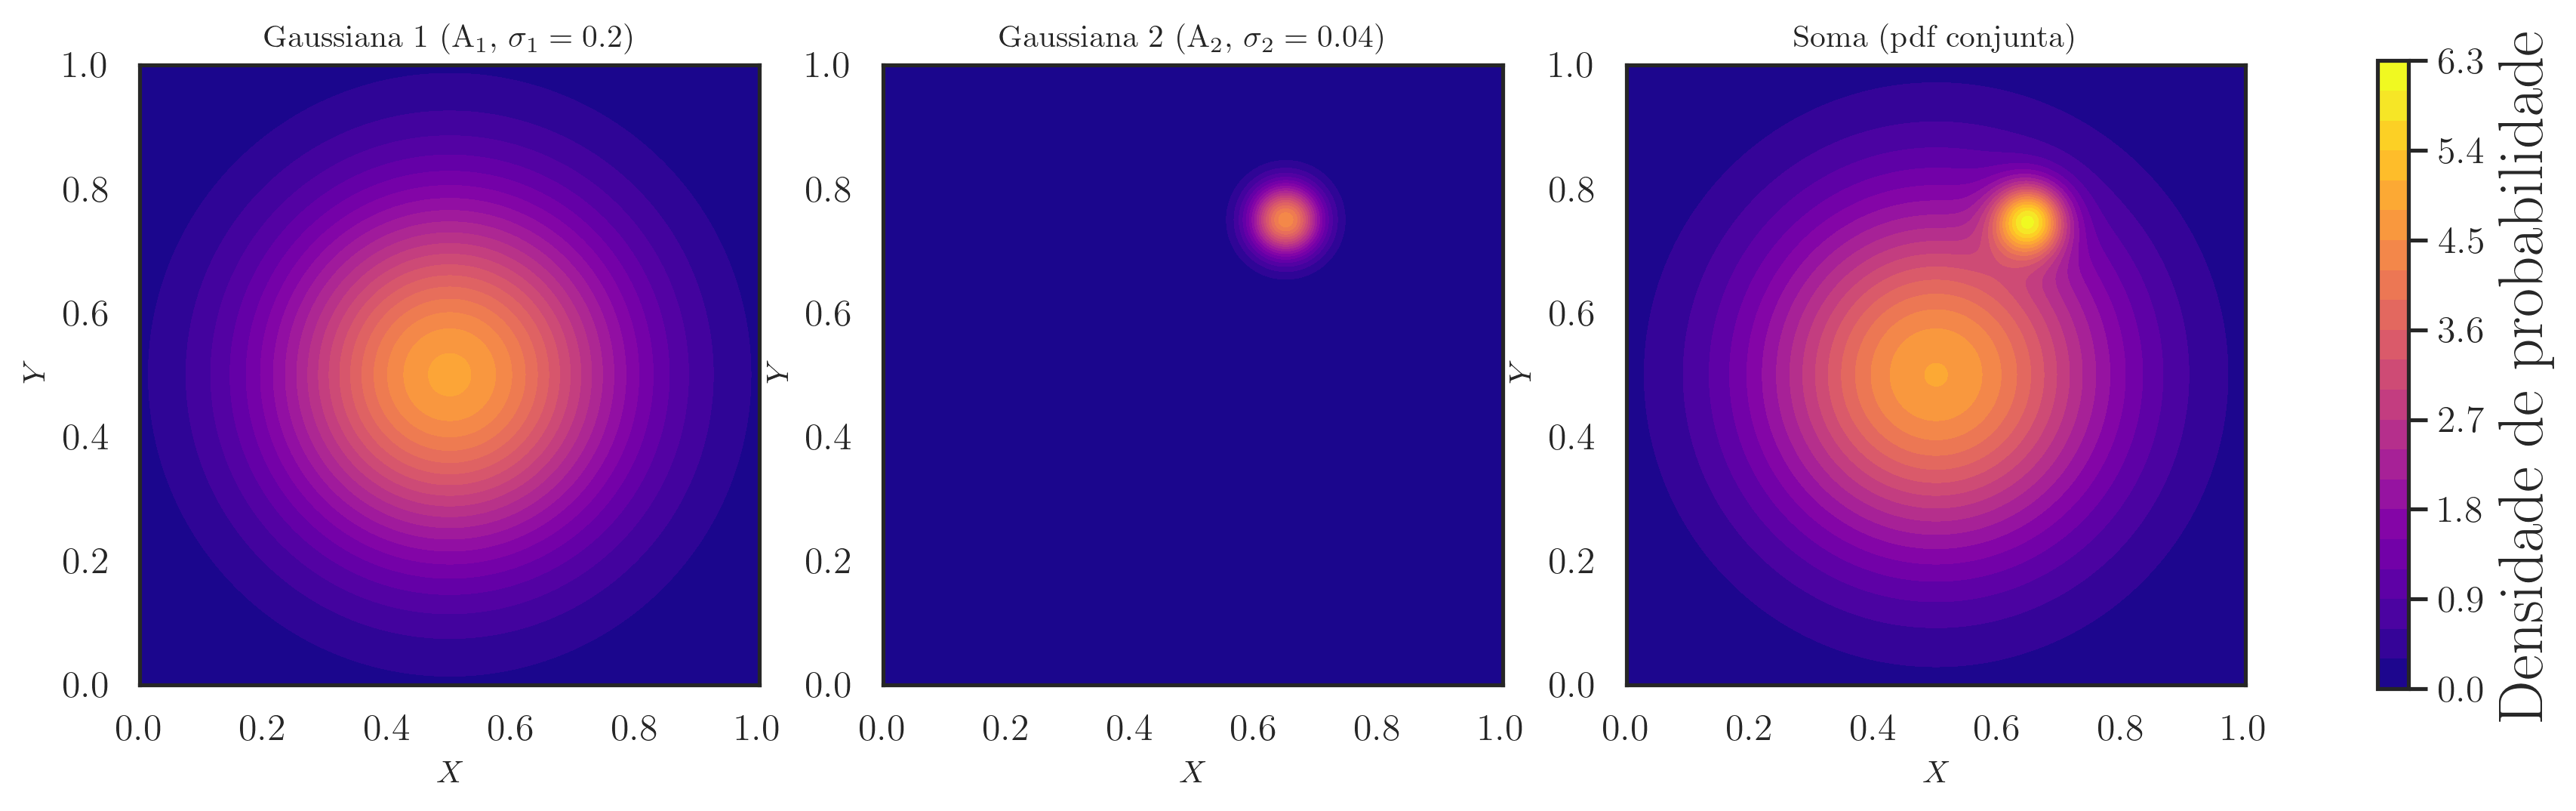

In [5]:
gauss1 = A1 * np.exp(-((X - x1)**2 + (Y - y1)**2) / (2 * sigma_1**2))
gauss2 = A2 * np.exp(-((X - x2)**2 + (Y - y2)**2) / (2 * sigma_2**2))

vmax = pdf.max() 

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), dpi=300)

titles = ['Gaussiana 1 (A$_1$, $\\sigma_1=0.2$)',
          'Gaussiana 2 (A$_2$, $\\sigma_2=0.04$)',
          'Soma (pdf conjunta)']
data = [gauss1, gauss2, pdf]

for ax, Z, title in zip(axs, data, titles):
    cf = ax.contourf(X, Y, Z, levels=20, cmap='plasma', vmin=0, vmax=vmax)
    ax.set_xlabel(r'$X$', fontsize=10)
    ax.set_ylabel(r'$Y$', fontsize=10)
    ax.set_title(title, fontsize=10)
    ax.set_aspect('equal')

fig.colorbar(cf, ax=axs, shrink=0.8, label='Densidade de probabilidade')
plt.show()

#### c. Distribuições marginais $p(X|D,M,I)$ e $p(Y|D,M,I)$

In [6]:
marginal_y = np.trapezoid(pdf, x, axis=1)
marginal_x = np.trapezoid(pdf, y, axis=0)

print(f"Integral em X antes da normalização: {np.trapezoid(marginal_x, x):.2f}") 
print(f"Integral em Y antes da normalização: {np.trapezoid(marginal_y, y):.2f}") 


norm_cte = np.trapezoid(marginal_x, x)
marginal_X = marginal_x / norm_cte
marginal_Y = marginal_y / norm_cte 

print(f"Integral em X após da normalização: {np.trapezoid(marginal_X, x):.2f}") 
print(f"Integral em Y após da normalização: {np.trapezoid(marginal_Y, y):.2f}")

Integral em X antes da normalização: 1.23
Integral em Y antes da normalização: 1.23
Integral em X após da normalização: 1.00
Integral em Y após da normalização: 1.00


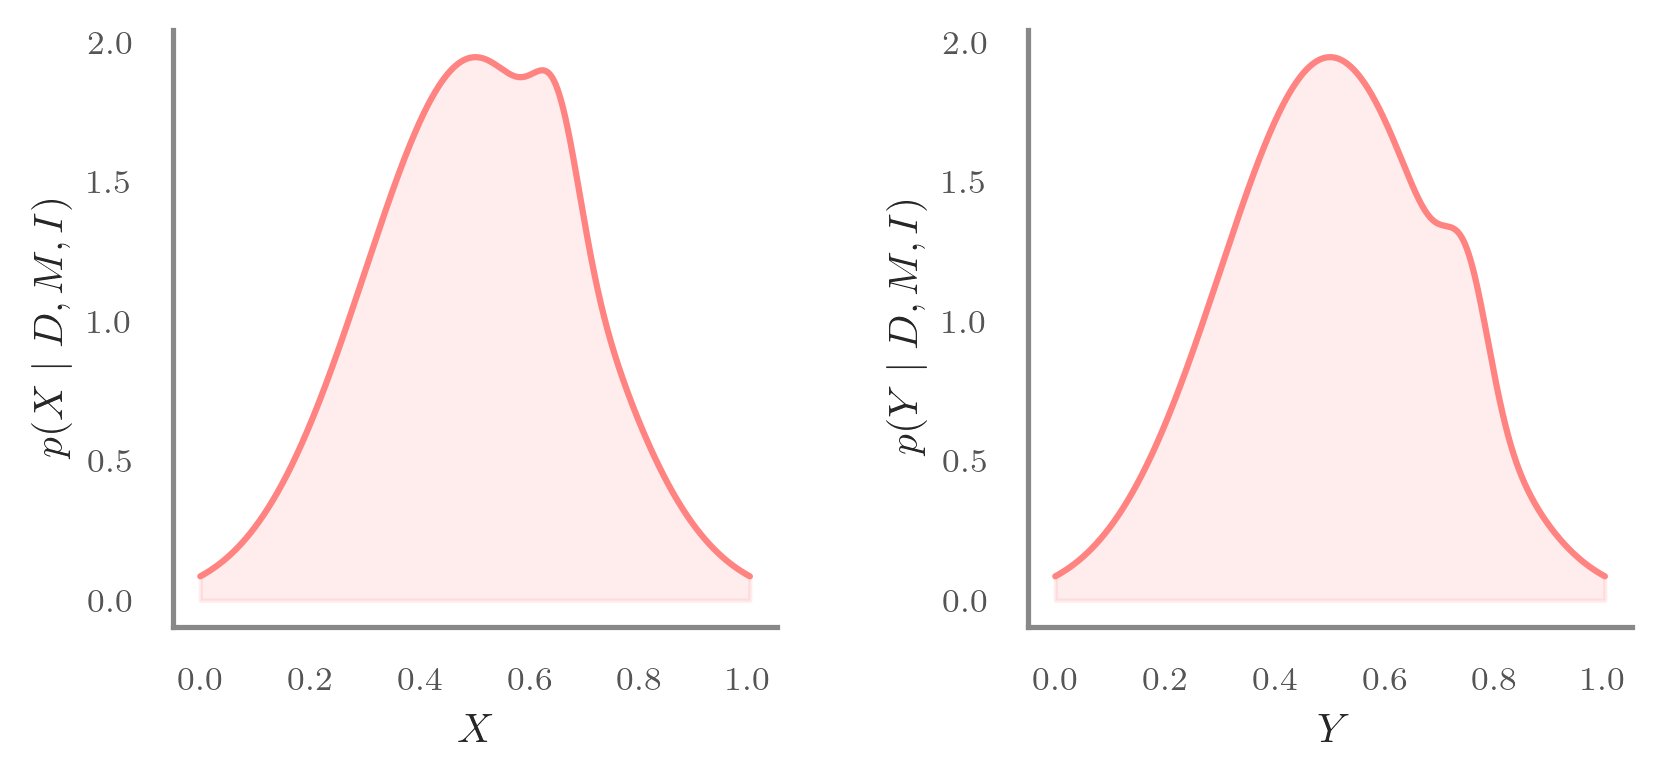

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3), dpi=300)

ax1.plot(x, marginal_X, color="#ff8381", linewidth=1.5)
ax1.fill_between(x, marginal_X, alpha=0.15, color='#ff8381')

ax1.spines[['top', 'right']].set_visible(False)
ax1.spines[['left', 'bottom']].set_color('#888')
ax1.tick_params(colors='#555', labelsize=8)
ax1.set_xlabel(r'$X$', fontsize=10)
ax1.set_ylabel(r'$p(X \mid D, M, I)$', fontsize=10)

ax2.plot(y, marginal_Y, color='#ff8381', linewidth=1.5)
ax2.fill_between(y, marginal_Y, alpha=0.15, color='#ff8381')

ax2.spines[['top', 'right']].set_visible(False)
ax2.spines[['left', 'bottom']].set_color('#888')
ax2.tick_params(colors='#555', labelsize=8)
ax2.set_xlabel(r'$Y$', fontsize=10)
ax2.set_ylabel(r'$p(Y \mid D, M, I)$', fontsize=10)

fig.tight_layout()
plt.show()

#### d, e. Função de densidade projetada e comparação com a marginal para $X$ e $Y$

In [8]:
proj_X = np.max(pdf, axis=0)
proj_Y = np.max(pdf, axis=1)

print(np.trapezoid(proj_X, x))
print(np.trapezoid(proj_Y, y))

# normalizando a projeção: 
norm_proj = proj_X / np.trapezoid(proj_X, x)
norm_proj_y = proj_Y / np.trapezoid(proj_Y, y)

print(np.trapezoid(norm_proj, x))
print(np.trapezoid(norm_proj_y, y))

2.5457668253773837
2.7284541897914285
1.0
1.0


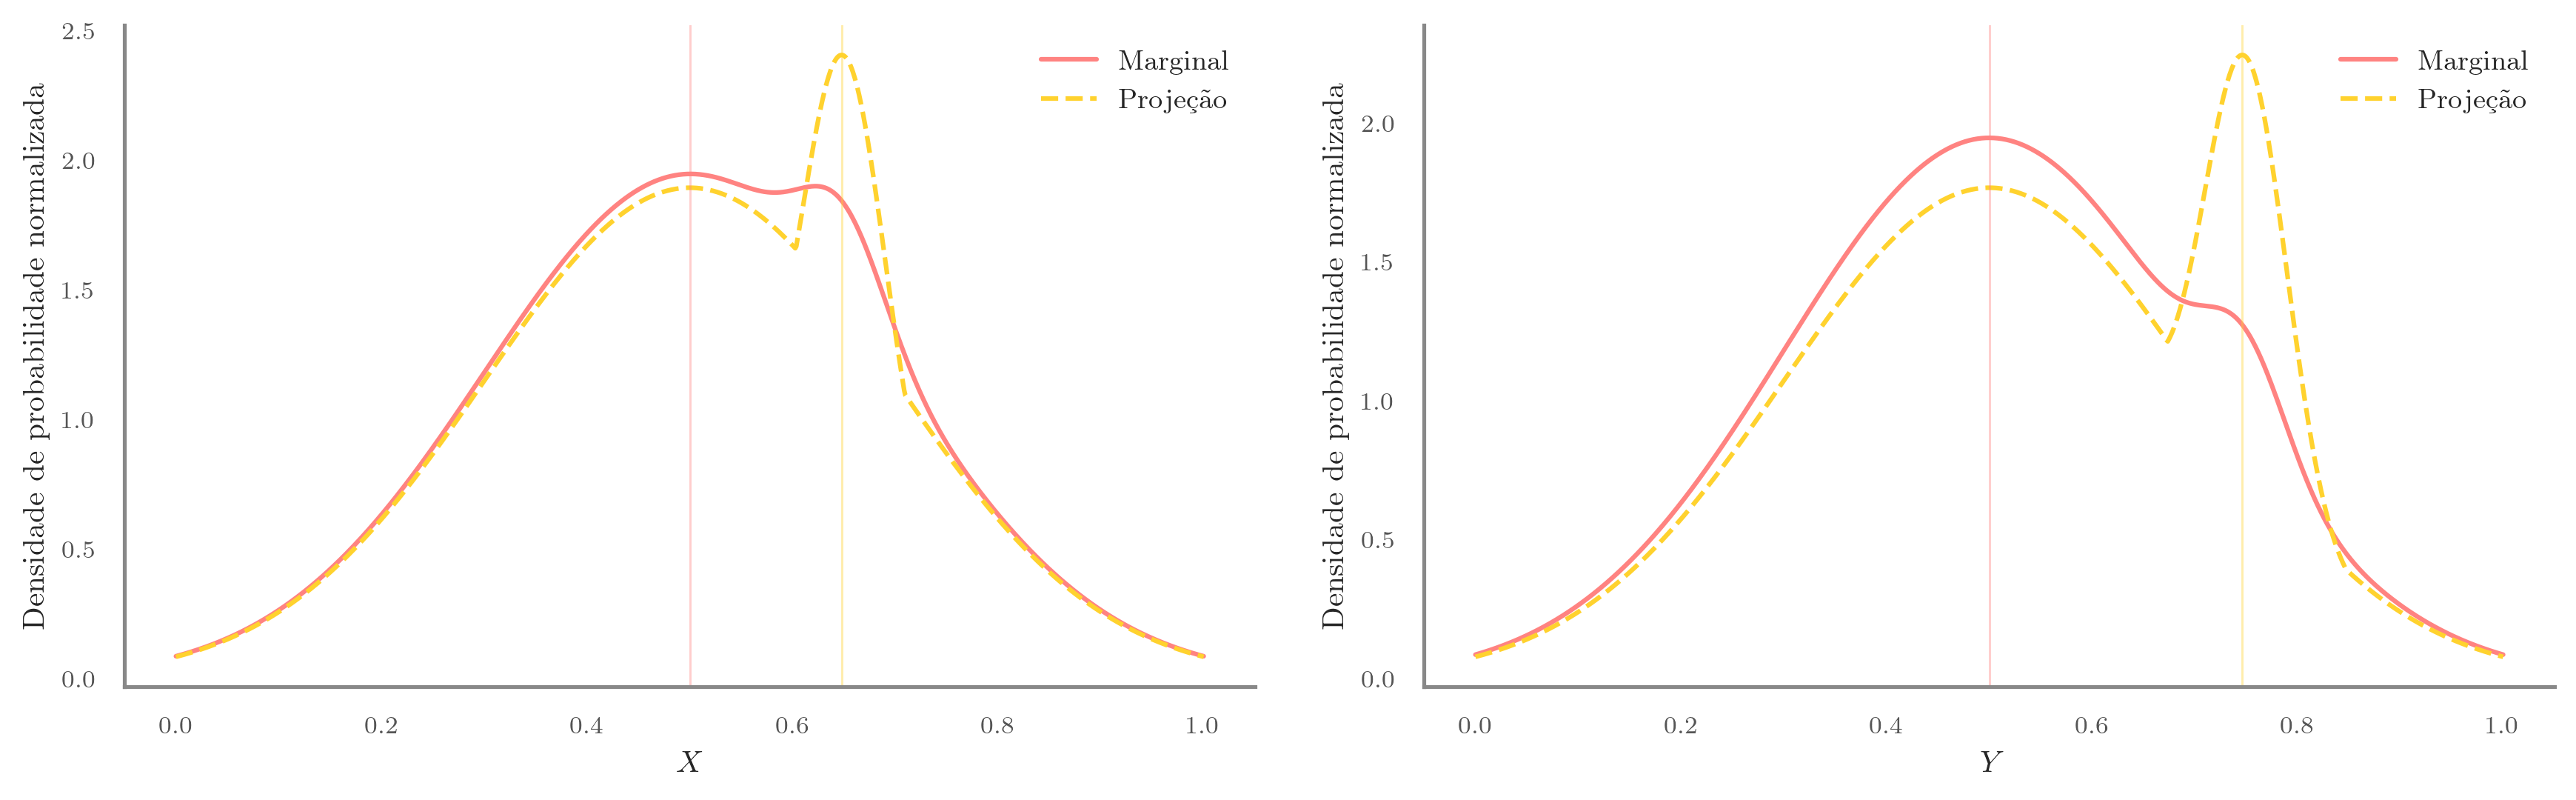

Pico da distribuição marginal em X = 0.5005005005005005
Pico da distribuição projetada em X = 0.6476476476476476
Pico da distribuição marginal em Y = 0.5005005005005005
Pico da distribuição projetada em Y = 0.7457457457457457


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), dpi=300)

ax = axs[0]
ax.plot(x, marginal_X, label='Marginal', color='#ff8381', linewidth=1.5)
ax.plot(x, norm_proj, label='Projeção', color='#ffd22e', linewidth=1.5, linestyle='--')

x_peak_marginal = x[np.argmax(marginal_X)]
x_peak_proj = x[np.argmax(norm_proj)]
ax.axvline(x_peak_marginal, color='#ff8381', linewidth=0.7, alpha=0.4)
ax.axvline(x_peak_proj, color='#ffd22e', linewidth=0.7, alpha=0.4)

ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#888')
ax.tick_params(colors='#555', labelsize=8)
ax.set_xlabel(r'$X$', fontsize=10)
ax.set_ylabel('Densidade de probabilidade normalizada', fontsize=10)
ax.legend(frameon=False, fontsize=9)

ax = axs[1]
ax.plot(y, marginal_Y, label='Marginal', color='#ff8381', linewidth=1.5)
ax.plot(y, norm_proj_y, label='Projeção', color='#ffd22e', linewidth=1.5, linestyle='--')

y_peak_marginal = y[np.argmax(marginal_Y)]
y_peak_proj = y[np.argmax(norm_proj_y)]
ax.axvline(y_peak_marginal, color='#ff8381', linewidth=0.7, alpha=0.4)
ax.axvline(y_peak_proj, color='#ffd22e', linewidth=0.7, alpha=0.4)

ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#888')
ax.tick_params(colors='#555', labelsize=8)
ax.set_xlabel(r'$Y$', fontsize=10)
ax.set_ylabel('Densidade de probabilidade normalizada', fontsize=10)
ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
plt.show()

print(f"Pico da distribuição marginal em X = {x_peak_marginal}")
print(f"Pico da distribuição projetada em X = {x_peak_proj}")
print(f"Pico da distribuição marginal em Y = {y_peak_marginal}")
print(f"Pico da distribuição projetada em Y = {y_peak_proj}")

### Problema 6:

#### a. Plote o gráfico dos dados:

In [10]:
channel = np.arange(1, 65)          

d = np.array([                     
    0.25, -0.19, 0.25, -0.56, -0.41, -0.94, 0.84, -0.30,
    -2.06, -1.39, 0.07, 1.80, -1.02, -0.46, 0.29, -0.36,
    -0.42, 1.43, -1.33, 0.06, 0.82, 0.42, 3.76, 1.10,
    1.31, 1.86, 0.32, -1.14, 1.24, -0.29, 0.02, -1.52,
    0.44, 0.05, 0.59, 0.94, -0.10, 0.57, 0.40, -0.97,
    2.20, 0.15, -0.37, -0.67, -0.05, -0.20, 0.65, -1.24,
    -1.56, -0.64, 0.48, 1.79, 0.07, 1.30, 0.29, -0.23,
    -0.50, 0.93, -1.28, -1.98, 1.85, 0.89, 0.65, 0.28
])

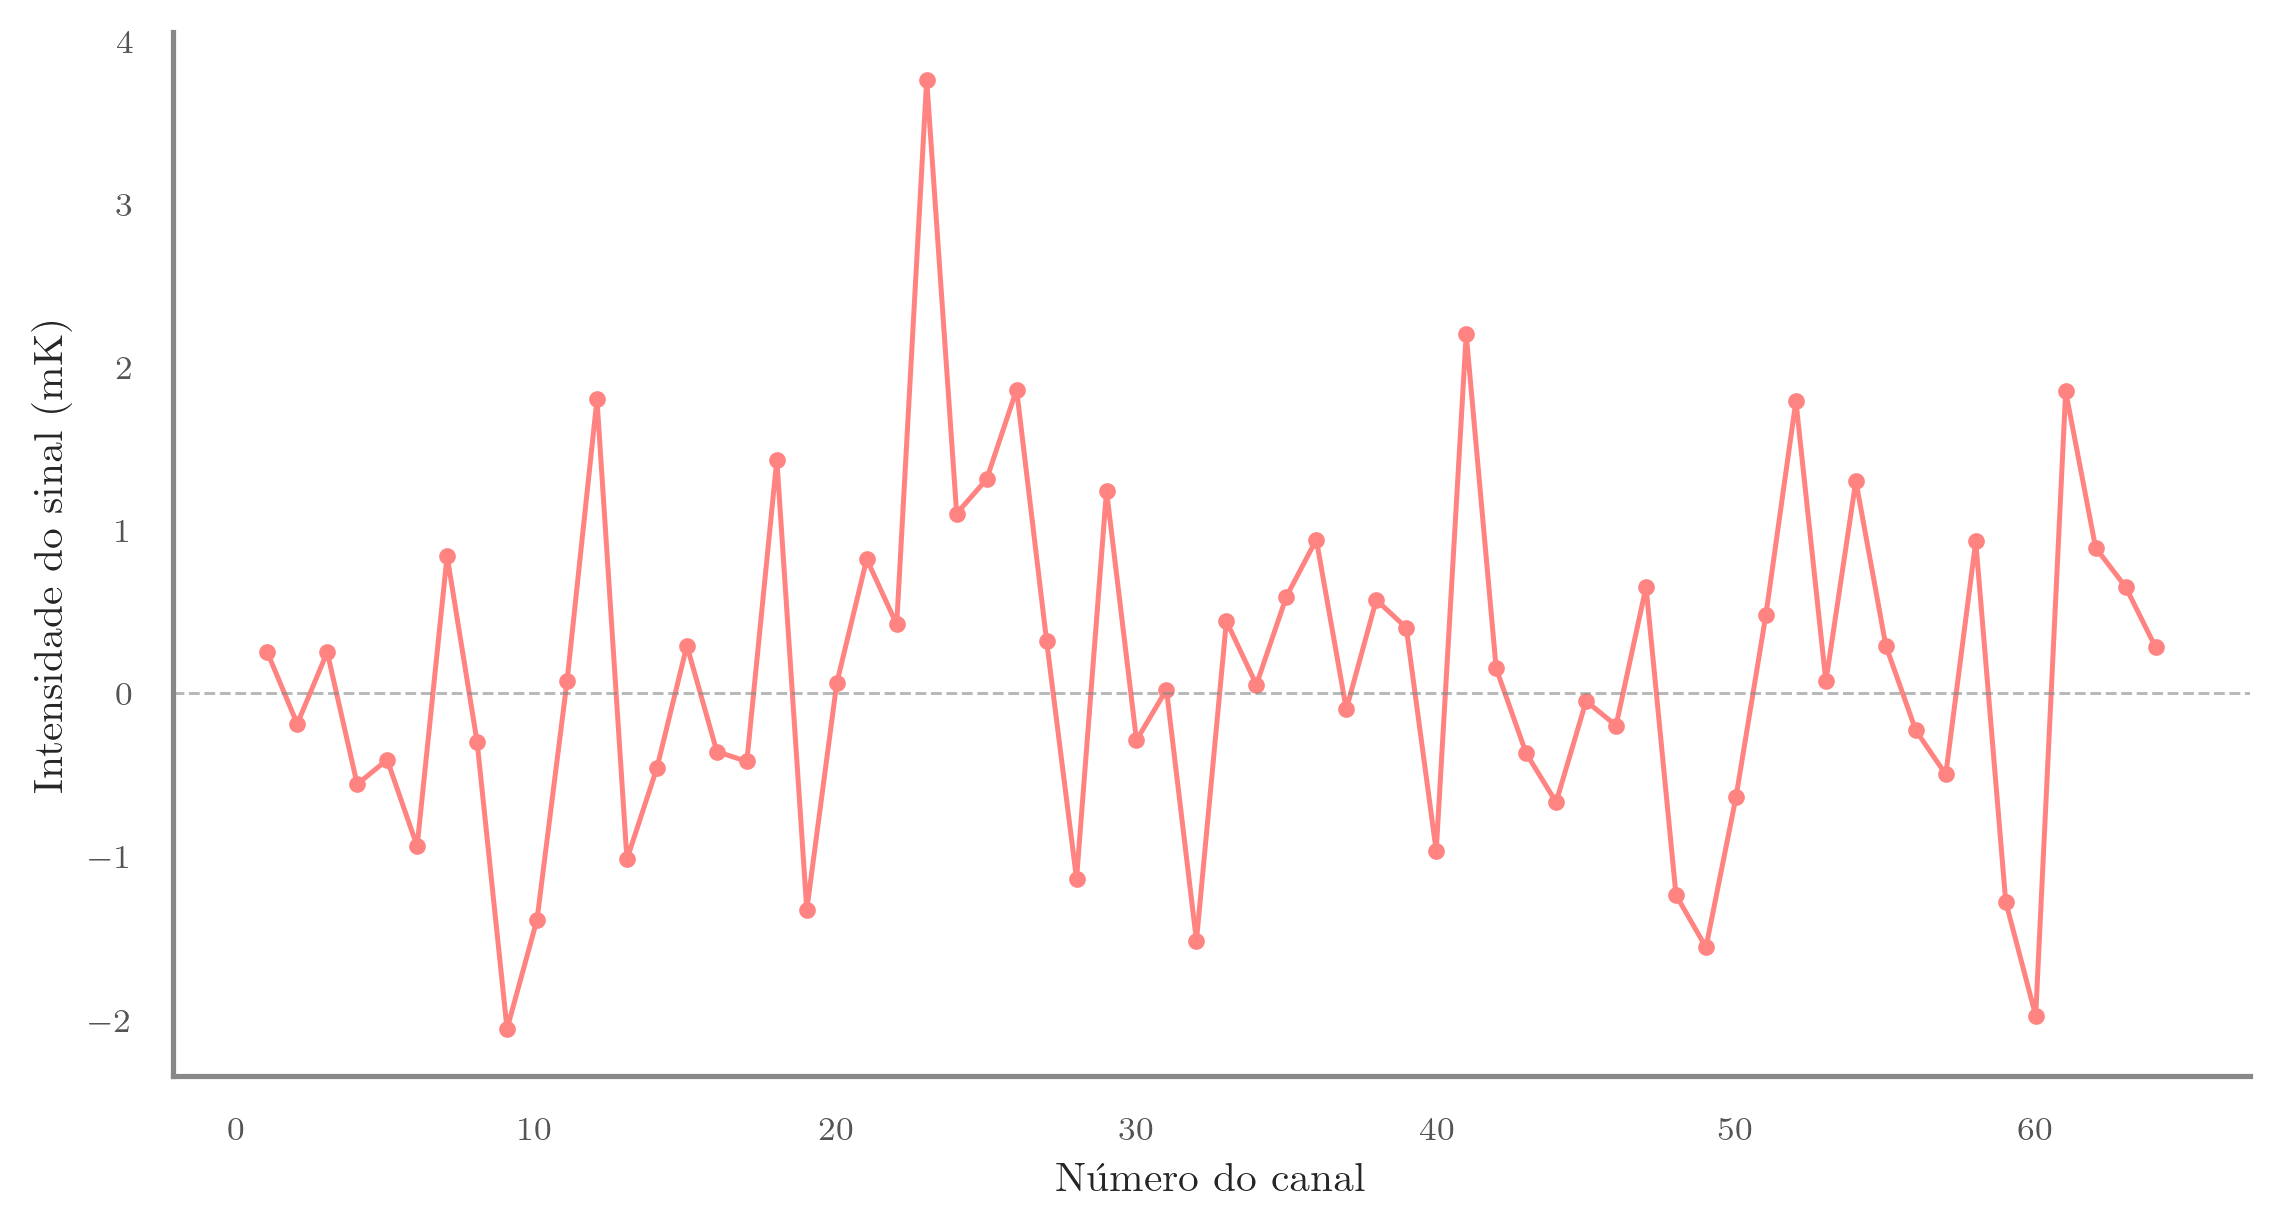

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)

ax.plot(channel, d, color='#ff8381', linewidth=1.2, marker='o', markersize=3)
ax.axhline(0, color='#888', linewidth=0.7, alpha=0.6, linestyle='--')

ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#888')
ax.tick_params(colors='#555', labelsize=8)
ax.set_xlabel('Número do canal', fontsize=10)
ax.set_ylabel('Intensidade do sinal (mK)', fontsize=10)

fig.tight_layout()
plt.show()

#### b. Compute a probabilidade posterior de $M_1$ para os casos com prior de Jeffreys e prior uniforme.

In [12]:
sigma_l = 2        
sigma_noise = 1.0  
v0 = 24            

In [13]:
def gaussian_shape(vi, v0, sigma_l):
    return np.exp(-(vi - v0)**2 / (2 * sigma_l**2))

fi = gaussian_shape(channel, v0, sigma_l)

fid = np.sum(fi * d)     # S1 = sum_i d_i * f_i 
fi2 = np.sum(fi**2)      # S2 = sum_i f_i^2

def rt(T, fid, fi2, sigma_noise):
    return np.exp((T * fid) / sigma_noise**2 - (T**2 * fi2) / (2 * sigma_noise**2))

Integrando sobre $T$ com cada um dos dois priors (uniforme e Jeffreys, Eqs. 3.33 e 3.38):

In [14]:
# prior uniforme

integrando_u = lambda T: rt(T, fid, fi2, sigma_noise)
integral_u, erro_u = scipy.integrate.quad(integrando_u, 0.1, 100)
odds_uniforme = (1 / (100 - 0.1)) * integral_u

# prior de Jeffrey

integrando_j = lambda T: rt(T, fid, fi2, sigma_noise) / T
integral_j, erro_j = scipy.integrate.quad(integrando_j, 0.1, 100)
odds_jeffreys = (1 / np.log(100 / 0.1)) * integral_j

In [15]:
#  Probabilidade posterior de M1

p_M1_uniform  = odds_uniforme / (1 + odds_uniforme)
p_M1_jeffreys = odds_jeffreys / (1 + odds_jeffreys)

print(f"S1 = {fid:.4f}")
print(f"S2 = {fi2:.4f}")
print(f"Razão uniforme  = {odds_uniforme:.4f}  -  p(M1|D,I) = {p_M1_uniform:.4f}")
print(f"Razão Jeffreys  = {odds_jeffreys:.4f}  -  p(M1|D,I) = {p_M1_jeffreys:.4f}")

S1 = 7.1883
S2 = 3.5449
Razão uniforme  = 19.4933  -  p(M1|D,I) = 0.9512
Razão Jeffreys  = 151.7905  -  p(M1|D,I) = 0.9935


#### d. Compute e plote a probabilidade posterior (densidade) considerando que $M_1$ é correto.

In [16]:
T_grid = np.linspace(0.1, 100, 1000)

def prior_uniform(T, Tmin=0.1, Tmax=100):
    return 1 / (Tmax - Tmin)

def prior_jeffreys(T, Tmin=0.1, Tmax=100):
    return 1 / (T * np.log(Tmax/Tmin))

num_unif  = prior_uniform(T_grid)  * rt(T_grid, fid, fi2, sigma_noise)
num_jeff  = prior_jeffreys(T_grid) * rt(T_grid, fid, fi2, sigma_noise)

Z_uniforme = np.trapezoid(num_unif, T_grid)
posterior_uniforme = num_unif / Z_uniforme

Z_jeffreys = np.trapezoid(num_jeff, T_grid)
posterior_jeffreys = num_jeff / Z_jeffreys

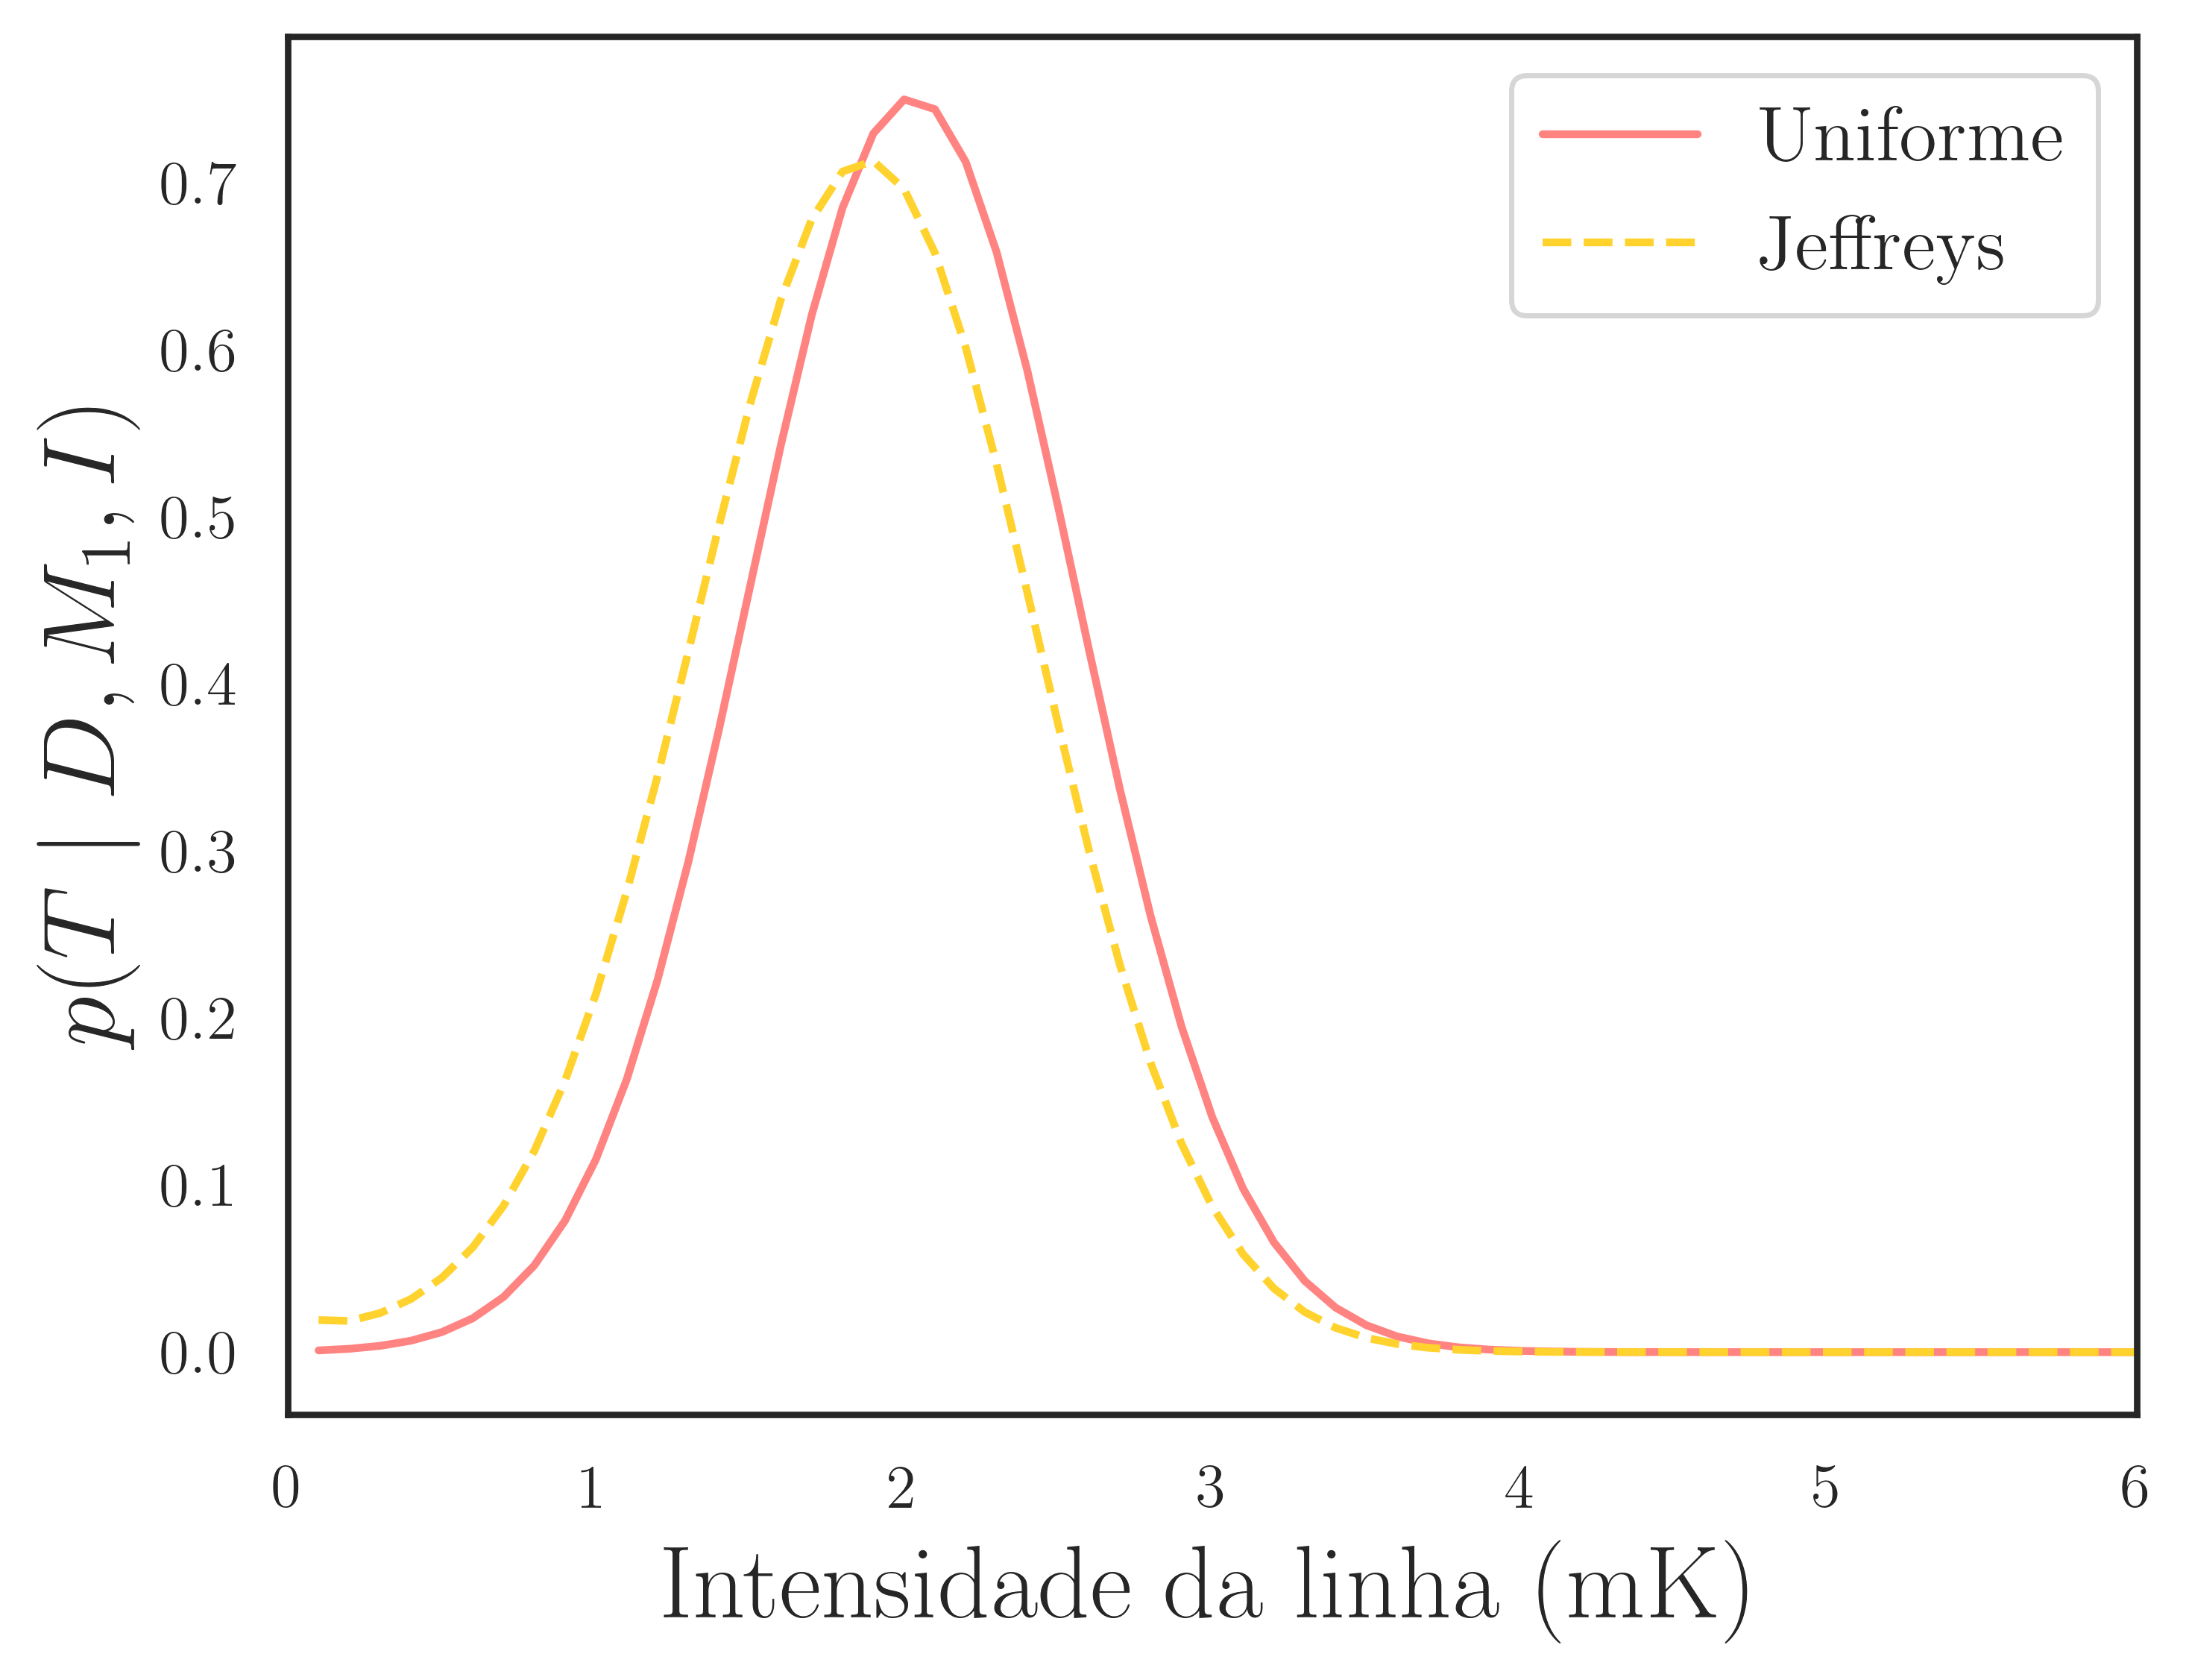

In [17]:
plt.plot(T_grid, posterior_uniforme, label='Uniforme', color='#ff8381')
plt.plot(T_grid, posterior_jeffreys, label='Jeffreys', color='#ffd22e', ls='--')
plt.xlabel('Intensidade da linha (mK)')
plt.ylabel(r'$p(T \mid D, M_1, I)$')
plt.xlim(0, 6)
plt.legend()
plt.show()

#### e. Valor mais provável e região de credibilidade de 95% para a intensidade da linha.

In [18]:
dT = T_grid[1] - T_grid[0]

p_unif_disc = posterior_uniforme * dT 
p_jeff_disc = posterior_jeffreys * dT 

def cred_regiao(x, y, C=0.95):
    idx_ord = np.argsort(y)[::-1]
    y_ord = y[idx_ord]
    x_ord = x[idx_ord]

    y_acum = np.cumsum(y_ord)
    cutoff_idx = np.searchsorted(y_acum, C)

    x_regiao = x_ord[:cutoff_idx + 1]

    return np.min(x_regiao), np.max(x_regiao)

lim_inf_u, lim_sup_u = cred_regiao(T_grid, p_unif_disc)
lim_inf_j, lim_sup_j = cred_regiao(T_grid, p_jeff_disc)

print("Intervalos de Credibilidade (95%):")
print(f"Prior Uniforme:  [{lim_inf_u:.2f}, {lim_sup_u:.2f}]")
print(f"Prior de Jeffreys: [{lim_inf_j:.2f}, {lim_sup_j:.2f}]")


Intervalos de Credibilidade (95%):
Prior Uniforme:  [1.00, 3.00]
Prior de Jeffreys: [0.70, 2.90]


In [19]:
T_moda_u = T_grid[np.argmax(posterior_uniforme)]
T_moda_j = T_grid[np.argmax(posterior_jeffreys)]

delta_sup_u = lim_sup_u - T_moda_u
delta_inf_u = T_moda_u - lim_inf_u

delta_sup_j = lim_sup_j - T_moda_j
delta_inf_j = T_moda_j - lim_inf_j

print(f"Prior Uniforme:  T = {T_moda_u:.2f} (+{delta_sup_u:.2f} / -{delta_inf_u:.2f}) mK")
print(f"Prior de Jeffreys: T = {T_moda_j:.2f} (+{delta_sup_j:.2f} / -{delta_inf_j:.2f}) mK")

Prior Uniforme:  T = 2.00 (+1.00 / -1.00) mK
Prior de Jeffreys: T = 1.90 (+1.00 / -1.20) mK


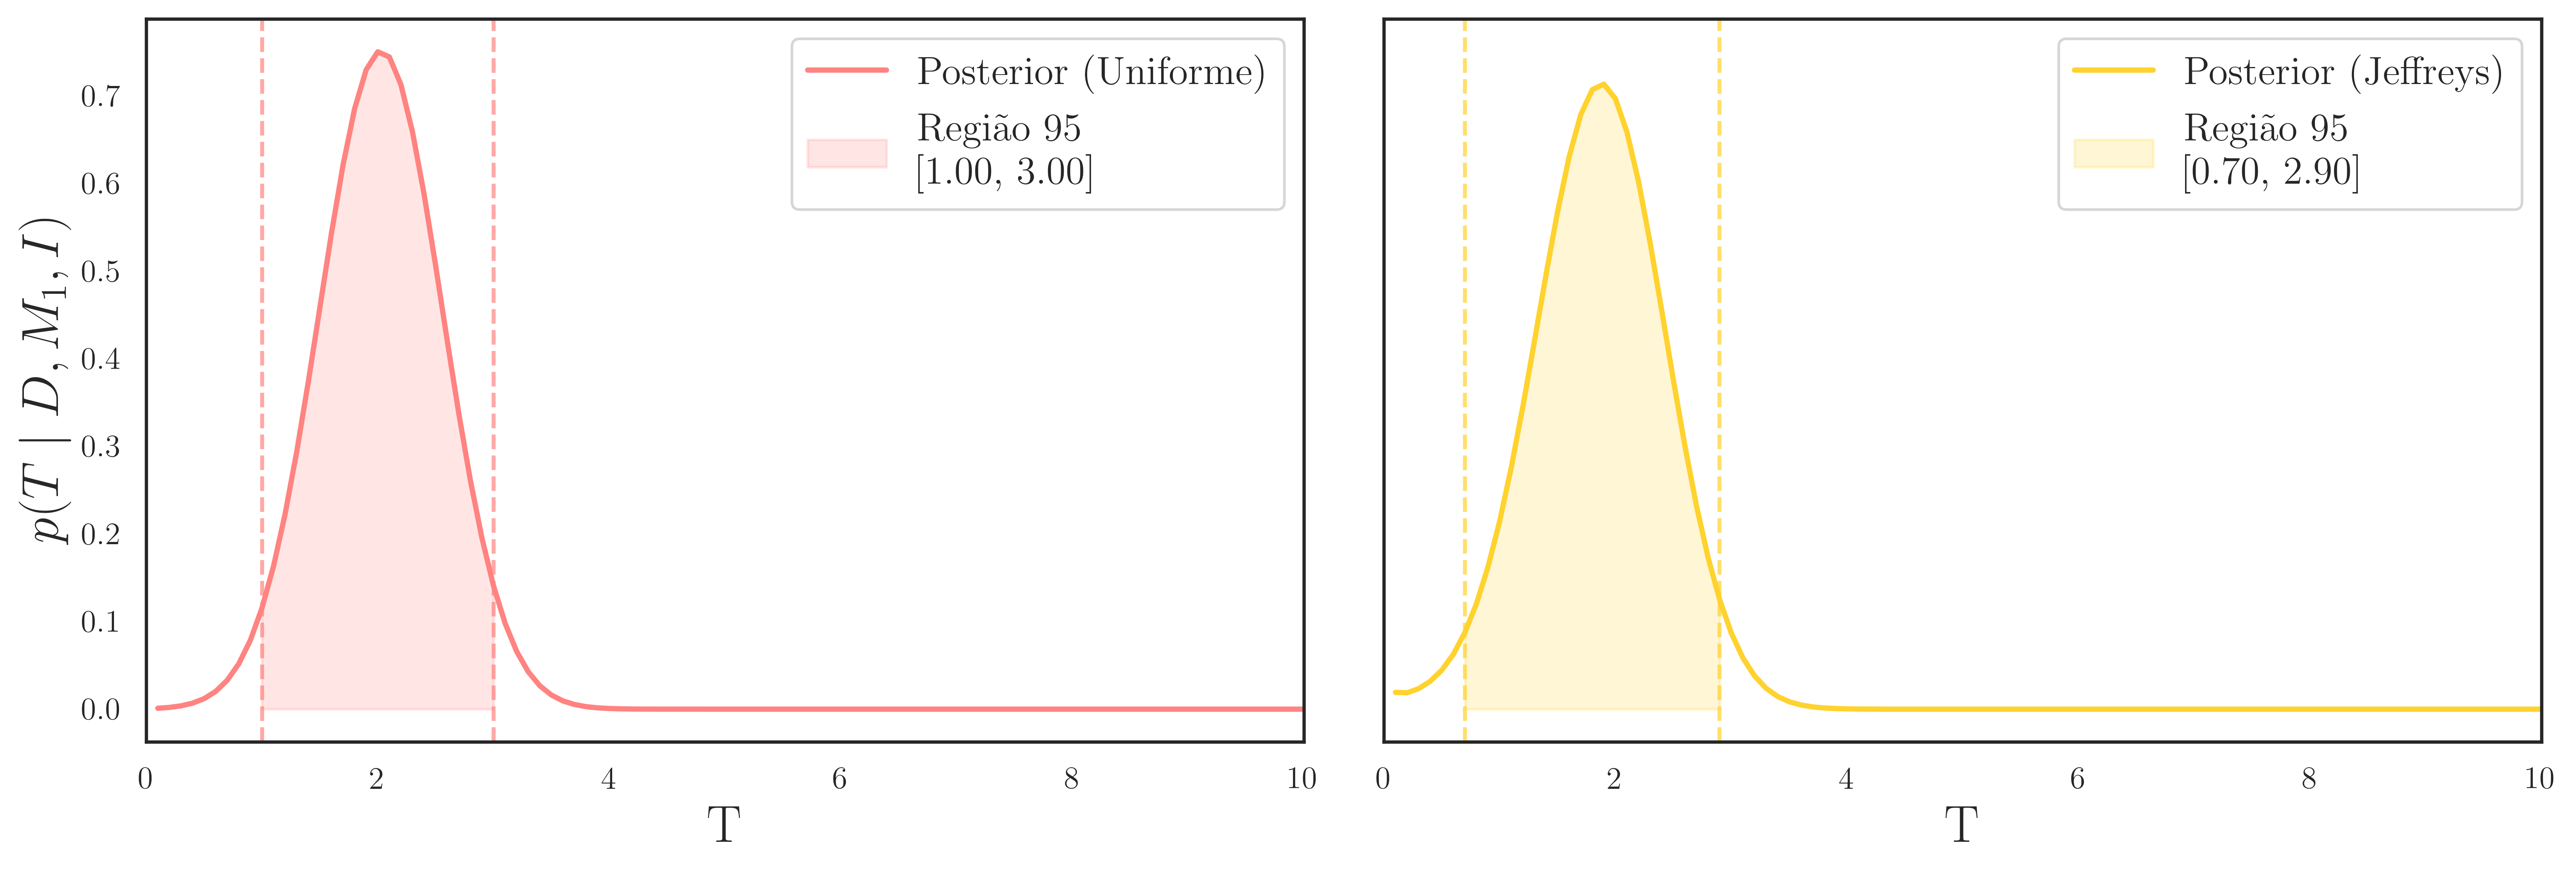

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax1.plot(T_grid, posterior_uniforme, label='Posterior (Uniforme)', color='#ff8381', lw=2)
regiao_u = (T_grid >= lim_inf_u) & (T_grid <= lim_sup_u)
ax1.fill_between(T_grid, posterior_uniforme, where=regiao_u, color='#ff8381', alpha=0.2, 
                 label=f'Região 95%\n[{lim_inf_u:.2f}, {lim_sup_u:.2f}]')
ax1.axvline(lim_inf_u, color='#ff8381', linestyle='--', alpha=0.7)
ax1.axvline(lim_sup_u, color='#ff8381', linestyle='--', alpha=0.7)
ax1.set_xlabel('T')
ax1.set_ylabel(r'$p(T \mid D, M_1, I)$')
ax1.set_xlim(0, 10) 
ax1.legend()

ax2.plot(T_grid, posterior_jeffreys, label='Posterior (Jeffreys)', color='#ffd22e', lw=2)
regiao_j = (T_grid >= lim_inf_j) & (T_grid <= lim_sup_j)
ax2.fill_between(T_grid, posterior_jeffreys, where=regiao_j, color='#ffd22e', alpha=0.2, 
                 label=f'Região 95%\n[{lim_inf_j:.2f}, {lim_sup_j:.2f}]')
ax2.axvline(lim_inf_j, color='#ffd22e', linestyle='--', alpha=0.7)
ax2.axvline(lim_sup_j, color='#ffd22e', linestyle='--', alpha=0.7)
ax2.set_xlabel('T')
ax2.set_xlim(0, 10)
ax2.legend()

plt.tight_layout()
plt.show()

#### f. Repita os cálculos de (b) e (d), agora assumindo que a posição da linha $v_0$ também é incerta, uniforme entre os canais 1 e 50.

**(b)**

In [21]:
v0_grid = np.arange(1, 51)

L_unif_v0 = np.zeros_like(v0_grid, dtype=float)
L_jeff_v0 = np.zeros_like(v0_grid, dtype=float)

for k, v0 in enumerate(v0_grid):
    fi = gaussian_shape(channel, v0, sigma_l)
    S1 = np.sum(fi * d)
    S2 = np.sum(fi**2)

    integrando_u = lambda T: rt(T, S1, S2, sigma_noise)
    integral_u, _ = scipy.integrate.quad(integrando_u, 0.1, 100)
    L_unif_v0[k] = integral_u / (100 - 0.1)

    integrando_j = lambda T: rt(T, S1, S2, sigma_noise) / T
    integral_j, _ = scipy.integrate.quad(integrando_j, 0.1, 100)
    L_jeff_v0[k] = integral_j / np.log(100 / 0.1)

prior_v0 = 1 / (50 - 1)

odds_uniforme_f  = prior_v0 * np.trapezoid(L_unif_v0, v0_grid)
odds_jeffreys_f  = prior_v0 * np.trapezoid(L_jeff_v0, v0_grid)

p_M1_uniform_f  = odds_uniforme_f / (1 + odds_uniforme_f)
p_M1_jeffreys_f = odds_jeffreys_f / (1 + odds_jeffreys_f)

print(f"Razão uniforme  = {odds_uniforme_f:.4f}  -  p(M1|D,I) = {p_M1_uniform_f:.4f}")
print(f"Razão Jeffreys  = {odds_jeffreys_f:.4f}  -  p(M1|D,I) = {p_M1_jeffreys_f:.4f}")

Razão uniforme  = 0.7521  -  p(M1|D,I) = 0.4293
Razão Jeffreys  = 6.3824  -  p(M1|D,I) = 0.8645


**(d)**

In [22]:
post_unif_2d = np.zeros((len(T_grid), len(v0_grid)))
post_jeff_2d = np.zeros((len(T_grid), len(v0_grid)))

for k, v0 in enumerate(v0_grid):
    fi = gaussian_shape(channel, v0, sigma_l)
    S1 = np.sum(fi * d)
    S2 = np.sum(fi**2)
    r_T = rt(T_grid, S1, S2, sigma_noise)

    post_unif_2d[:, k] = prior_uniform(T_grid) * (1/(50-1)) * r_T
    post_jeff_2d[:, k] = prior_jeffreys(T_grid) * (1/(50-1)) * r_T

marg_unif = np.trapezoid(post_unif_2d, v0_grid, axis=1)
marg_jeff = np.trapezoid(post_jeff_2d, v0_grid, axis=1)

# normaliza em T
posterior_uniforme_f = marg_unif / np.trapezoid(marg_unif, T_grid)
posterior_jeffreys_f = marg_jeff / np.trapezoid(marg_jeff, T_grid)


In [23]:
dT_f = T_grid[1] - T_grid[0]

p_unif_disc_f = posterior_uniforme_f * dT_f
p_jeff_disc_f = posterior_jeffreys_f * dT_f

lim_inf_u_f, lim_sup_u_f = cred_regiao(T_grid, p_unif_disc_f)
lim_inf_j_f, lim_sup_j_f = cred_regiao(T_grid, p_jeff_disc_f)

T_moda_u_f = T_grid[np.argmax(posterior_uniforme_f)]
T_moda_j_f = T_grid[np.argmax(posterior_jeffreys_f)]

print("Item (f)-(e): valor mais provável e RC 95% (com v0 incerto)")
print(f"Prior Uniforme:  T = {T_moda_u_f:.2f} (+{lim_sup_u_f-T_moda_u_f:.2f} / -{T_moda_u_f-lim_inf_u_f:.2f}) mK   RC95%=[{lim_inf_u_f:.2f}, {lim_sup_u_f:.2f}]")
print(f"Prior Jeffreys:  T = {T_moda_j_f:.2f} (+{lim_sup_j_f-T_moda_j_f:.2f} / -{T_moda_j_f-lim_inf_j_f:.2f}) mK   RC95%=[{lim_inf_j_f:.2f}, {lim_sup_j_f:.2f}]")

Item (f)-(e): valor mais provável e RC 95% (com v0 incerto)
Prior Uniforme:  T = 2.00 (+1.00 / -1.10) mK   RC95%=[0.90, 3.00]
Prior Jeffreys:  T = 1.80 (+1.00 / -1.70) mK   RC95%=[0.10, 2.80]


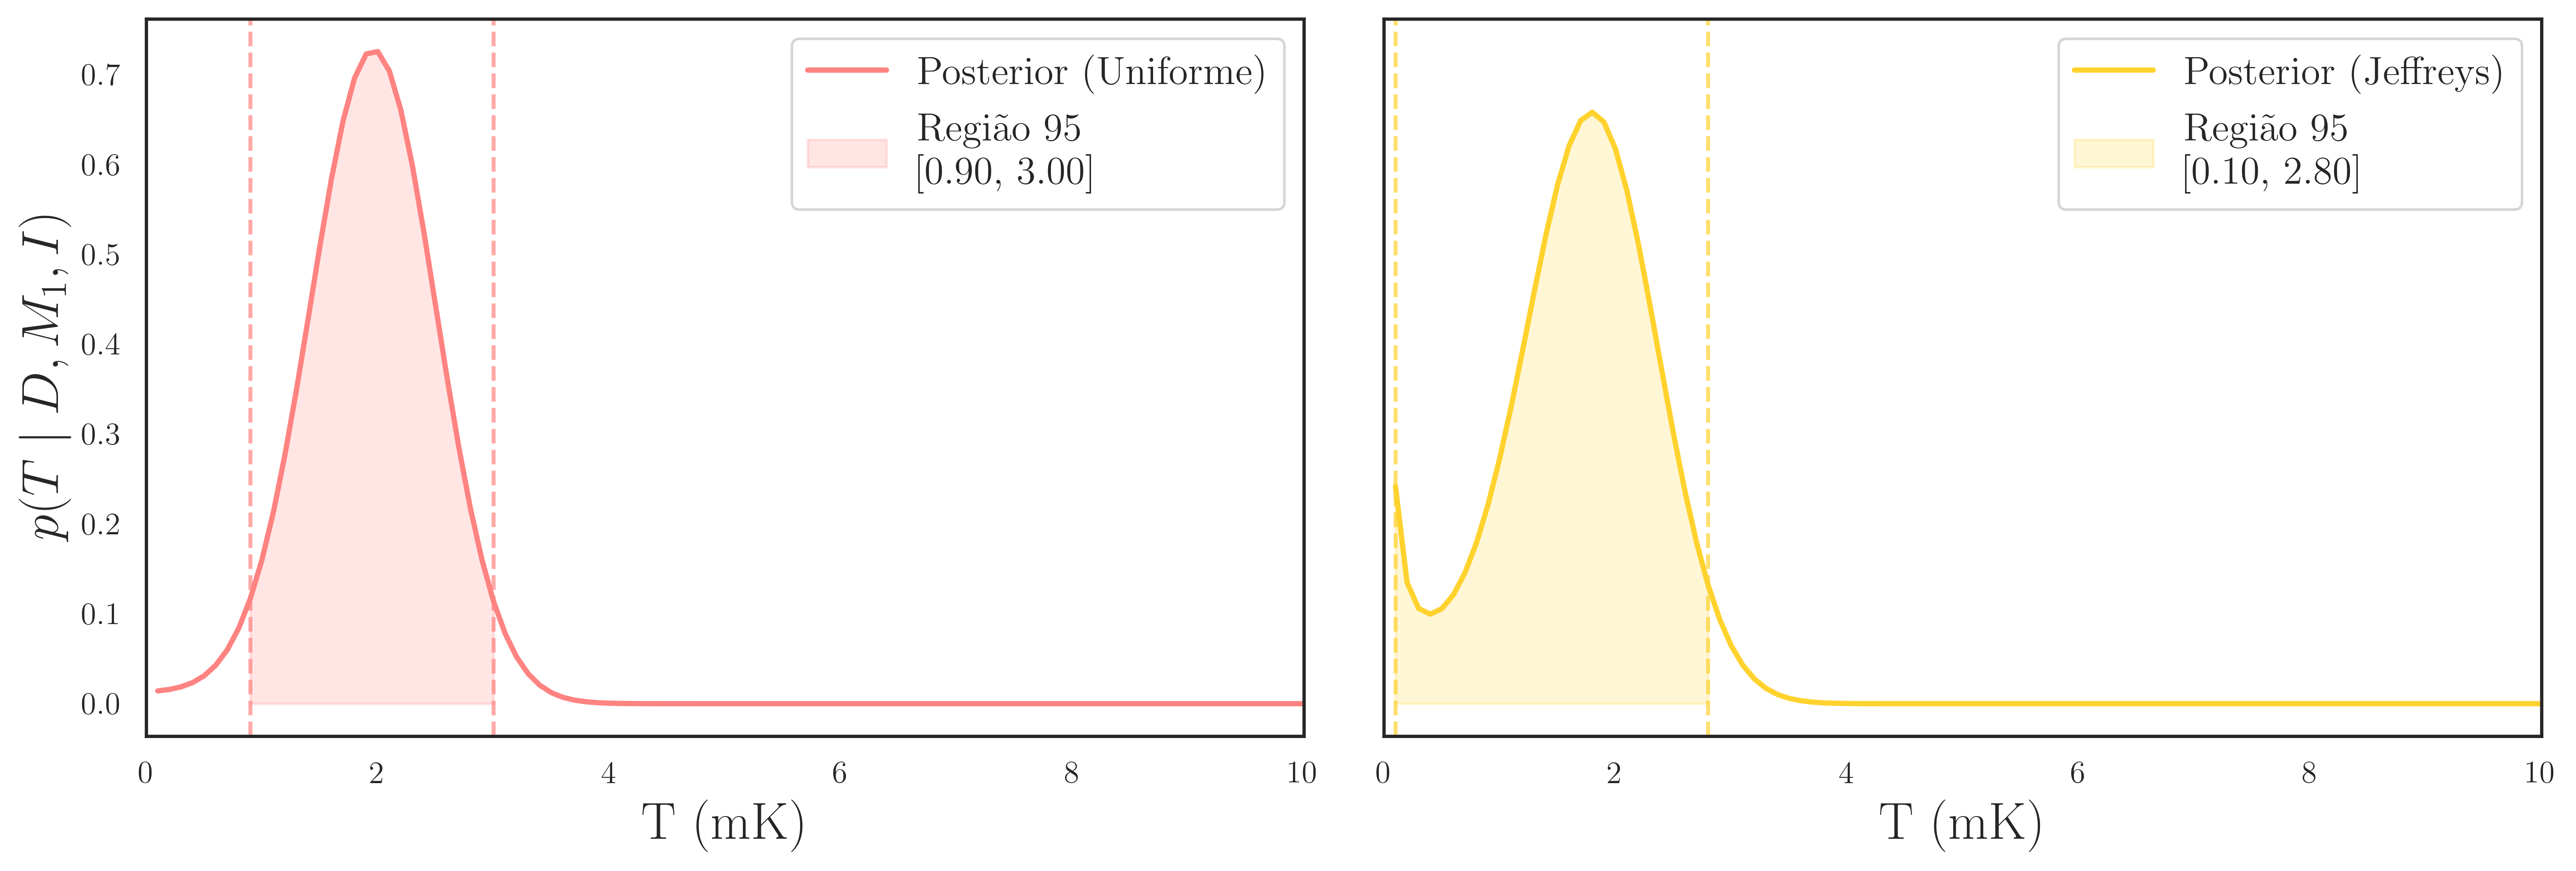

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax1.plot(T_grid, posterior_uniforme_f, label='Posterior (Uniforme)', color='#ff8381', lw=2)
regiao_u_f = (T_grid >= lim_inf_u_f) & (T_grid <= lim_sup_u_f)
ax1.fill_between(T_grid, posterior_uniforme_f, where=regiao_u_f, color='#ff8381', alpha=0.2,
                 label=f'Região 95%\n[{lim_inf_u_f:.2f}, {lim_sup_u_f:.2f}]')
ax1.axvline(lim_inf_u_f, color='#ff8381', linestyle='--', alpha=0.7)
ax1.axvline(lim_sup_u_f, color='#ff8381', linestyle='--', alpha=0.7)
ax1.set_xlabel('T (mK)')
ax1.set_ylabel(r'$p(T \mid D, M_1, I)$')
ax1.set_xlim(0, 10)
ax1.legend()

ax2.plot(T_grid, posterior_jeffreys_f, label='Posterior (Jeffreys)', color='#ffd22e', lw=2)
regiao_j_f = (T_grid >= lim_inf_j_f) & (T_grid <= lim_sup_j_f)
ax2.fill_between(T_grid, posterior_jeffreys_f, where=regiao_j_f, color='#ffd22e', alpha=0.2,
                 label=f'Região 95%\n[{lim_inf_j_f:.2f}, {lim_sup_j_f:.2f}]')
ax2.axvline(lim_inf_j_f, color='#ffd22e', linestyle='--', alpha=0.7)
ax2.axvline(lim_sup_j_f, color='#ffd22e', linestyle='--', alpha=0.7)
ax2.set_xlabel('T (mK)')
ax2.set_xlim(0, 10)
ax2.legend()

plt.tight_layout()
plt.show()

#### g. Calcule e plote as probabilidades marginais a posteriori para a frequência da linha.

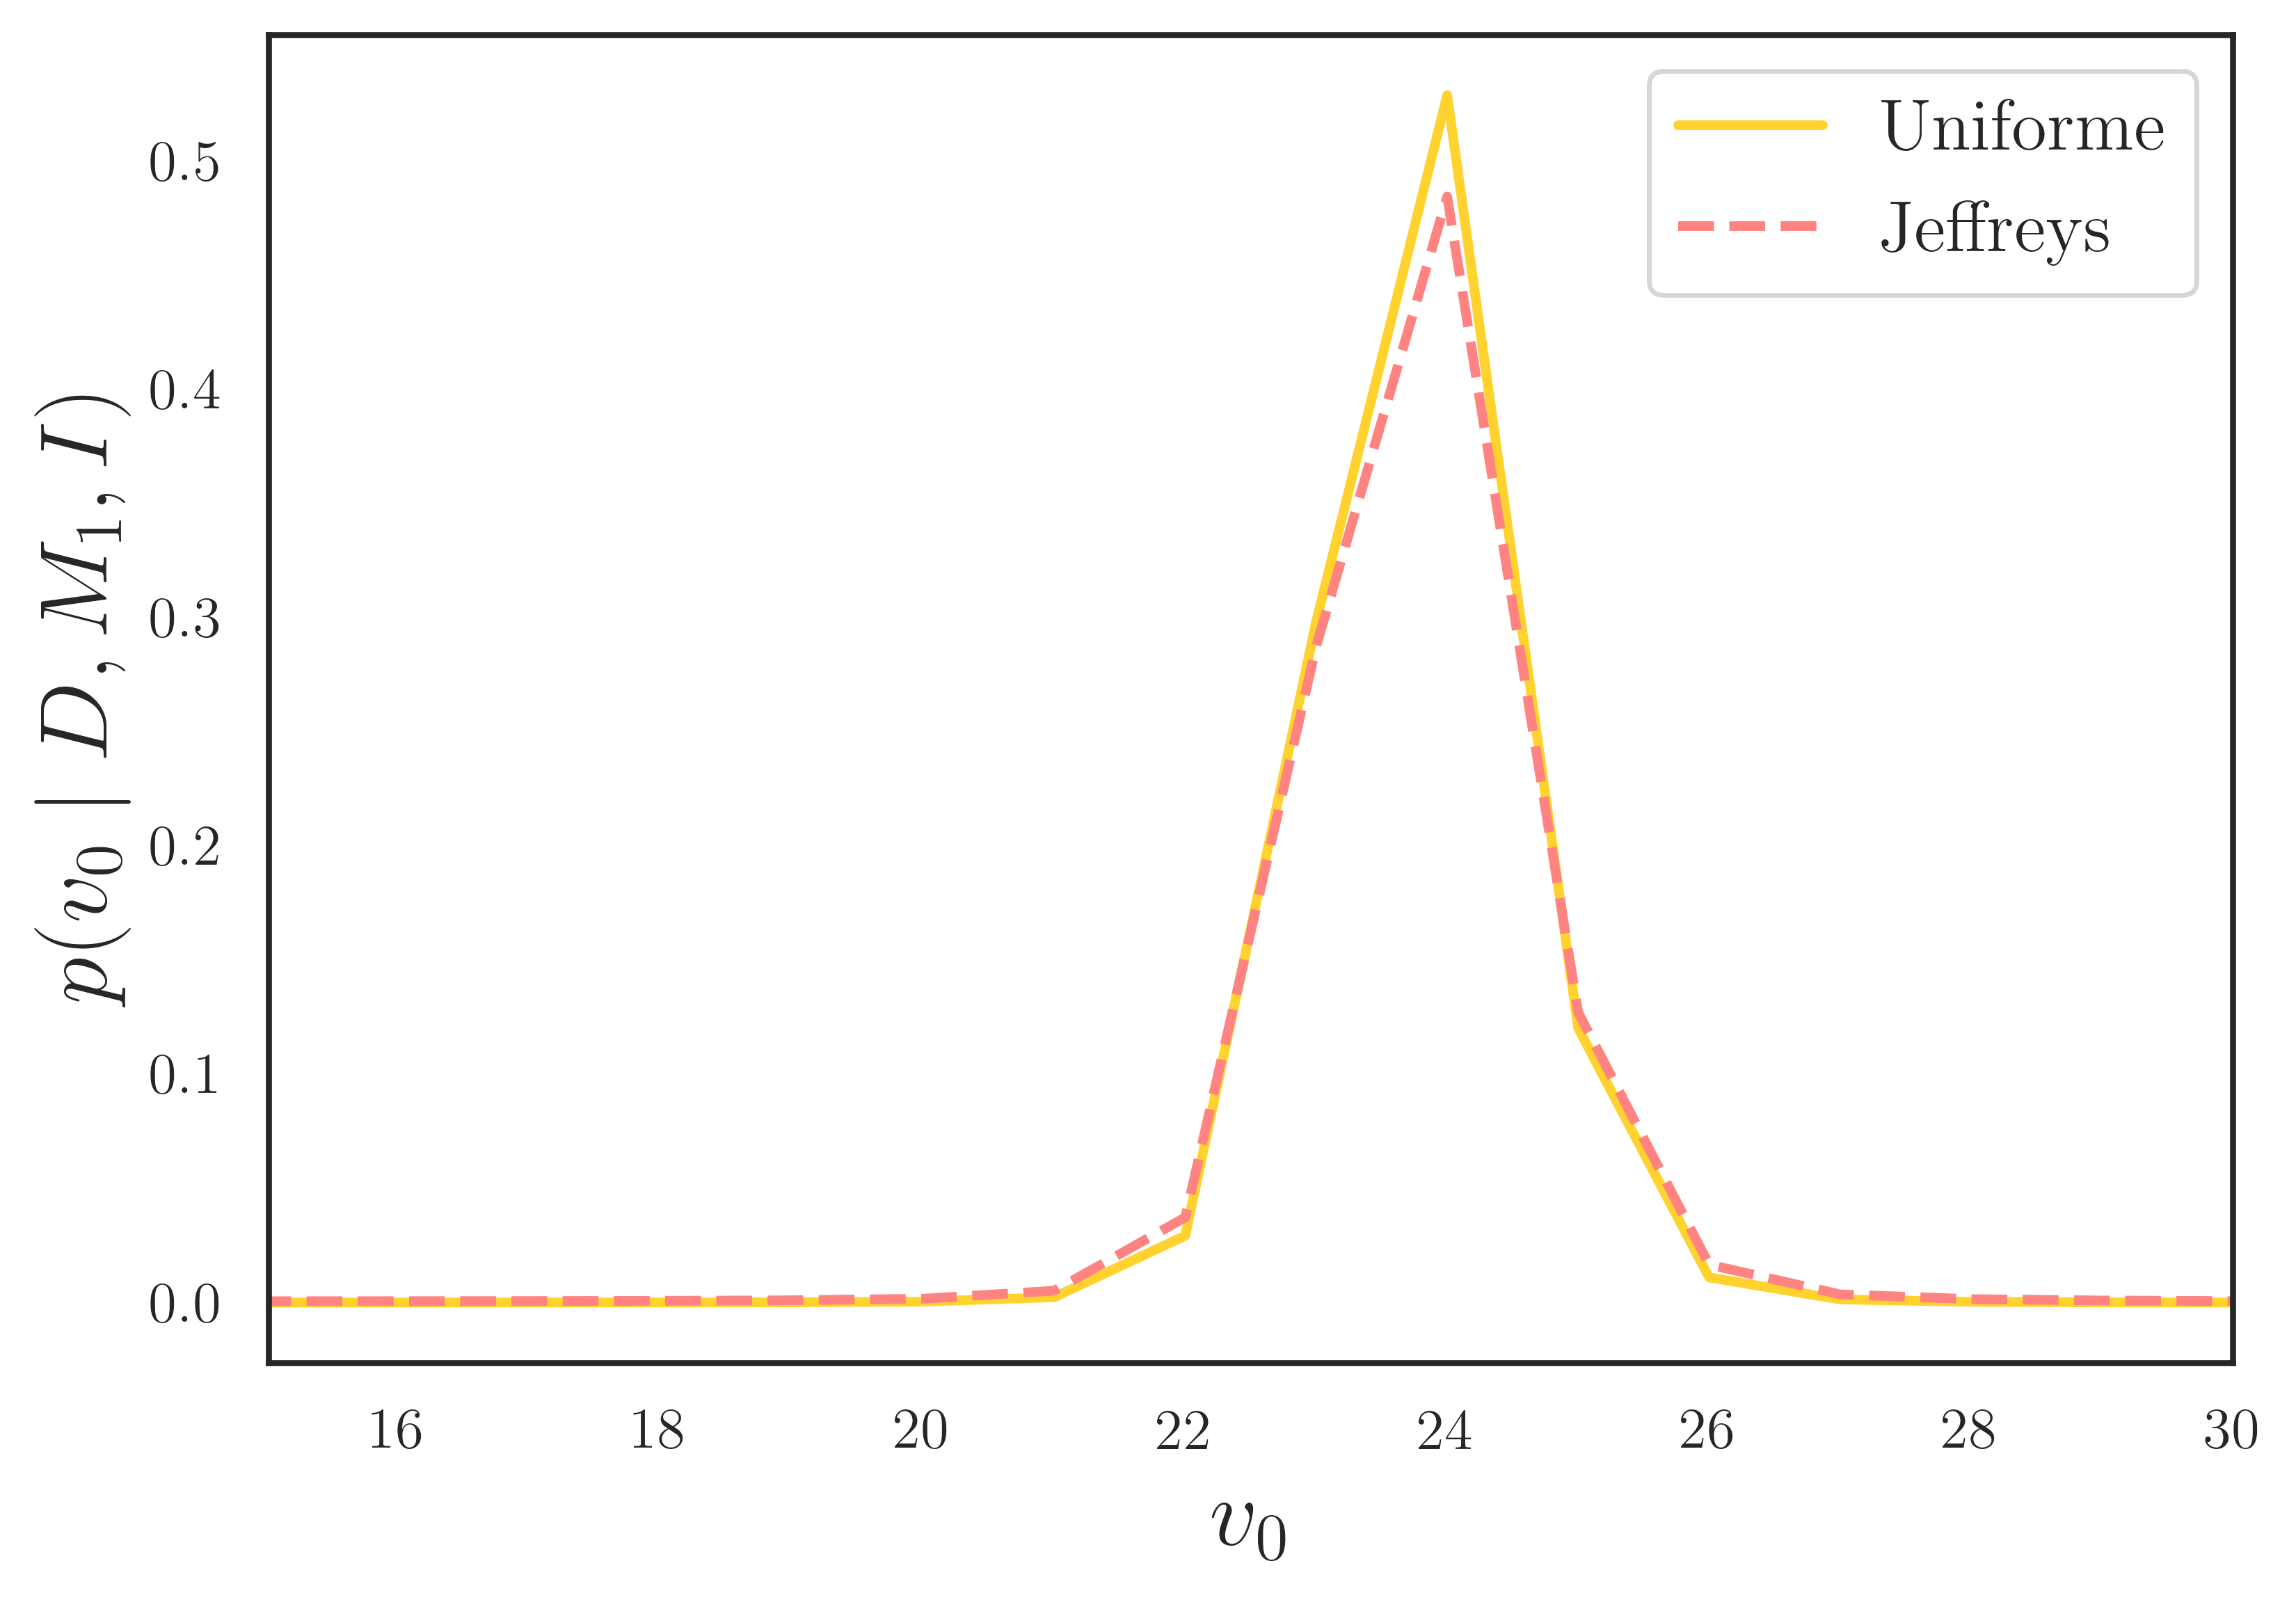

In [25]:
marg_freq_unif = np.trapezoid(post_unif_2d, T_grid, axis=0)
marg_freq_jeff = np.trapezoid(post_jeff_2d, T_grid, axis=0)

marg_freq_unif_norm = marg_freq_unif / np.trapezoid(marg_freq_unif, v0_grid)
marg_freq_jeff_norm = marg_freq_jeff / np.trapezoid(marg_freq_jeff, v0_grid)

plt.figure(figsize=(7,5))
plt.plot(v0_grid, marg_freq_unif_norm, label='Uniforme', lw=2, color='#ffd22e')
plt.plot(v0_grid, marg_freq_jeff_norm, label='Jeffreys', lw=2, ls='--', color='#ff8381')
plt.xlabel('$v_0$')
plt.ylabel(r'$p(v_0 \mid D, M_1, I)$')
plt.xlim(15,30)
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
v0_moda_u = v0_grid[np.argmax(marg_freq_unif_norm)]
v0_moda_j = v0_grid[np.argmax(marg_freq_jeff_norm)]

print(f"Canal mais provável (prior Uniforme para T): {v0_moda_u}")
print(f"Canal mais provável (prior Jeffreys para T):  {v0_moda_j}")

Canal mais provável (prior Uniforme para T): 24
Canal mais provável (prior Jeffreys para T):  24


#### h. Que fator de Occam adicional está associado a marginalizar sobre o intervalo de frequência da linha?

In [27]:
occam_v0_uniforme = odds_uniforme_f / odds_uniforme
occam_v0_jeffreys = odds_jeffreys_f / odds_jeffreys

print(f"Fator de Occam (v0), prior uniforme para T:  {occam_v0_uniforme:.4f}")
print(f"Fator de Occam (v0), prior Jeffreys para T:   {occam_v0_jeffreys:.4f}")

Fator de Occam (v0), prior uniforme para T:  0.0386
Fator de Occam (v0), prior Jeffreys para T:   0.0420
